INSTALL PANDAS NLTK

In [ ]:
# Jika belum ter-install, jalankan baris ini di terminal Anda:
!pip install pandas nltk

In [ ]:
# Import library yang akan kita gunakan
import pandas as pd
import re
import nltk

# Download modul 'stopwords' (kata-kata umum) dan 'punkt' (untuk tokenisasi) dari NLTK
# Ini hanya perlu dijalankan sekali
nltk.download('stopwords')
nltk.download('punkt')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

print("Library dan modul NLTK siap digunakan.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Library dan modul NLTK siap digunakan.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**MENAMPILKAN DATA**

In [ ]:
# Import library yang akan kita gunakan
import pandas as pd
import re
import nltk

# Tentukan nama file Anda
file_path ='/content/drive/MyDrive/SNA/HASIL_GABUNGAN.xlsx'

# Muat dataset ke dalam DataFrame pandas using read_excel
try:
    df = pd.read_excel(file_path)
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
    df = None # Set df to None or handle the error as appropriate


# Tampilkan 5 baris pertama untuk melihat data
if df is not None:
    print("Data Awal (5 baris pertama):")
    print(df.head())

    # Tampilkan informasi dataset (nama kolom, tipe data, data non-null)
    print("\nInformasi Dataset:")
    df.info()

Data Awal (5 baris pertama):
   conversation_id_str                      created_at  favorite_count  \
0  1975712432313291008  Tue Oct 07 23:58:45 +0000 2025               0   
1  1975703665651618048  Tue Oct 07 23:23:55 +0000 2025               0   
2  1975699846775681024  Tue Oct 07 23:08:44 +0000 2025               0   
3  1975699692962127872  Tue Oct 07 23:08:08 +0000 2025               0   
4  1975649870095524096  Tue Oct 07 19:50:09 +0000 2025               0   

                                           full_text               id_str  \
0  BUKU TKA BANK SOAL TKA SMP/MTS 2026 (Sesuai Pe...  1975712432313291008   
1  Lucunyaa mana murah bgt lagi Shopee : https://...  1975703665651618048   
2  Beli NMAX juga lebih murah di TikTok Shop Coba...  1975699846775681024   
3  Beli Alphard lebih murah di TikTok Shop loh Co...  1975699692962127872   
4  Ok TikTok shop is legit. (IYKYK) https://t.co/...  1975649870095524096   

                                           image_url in_reply_t

**FILTERING DATA**

In [ ]:
# 1. Filter Bahasa
# Kita hanya akan menganalisis tweet berbahasa Indonesia
df_filtered = df[df['lang'] == 'in'].copy()
print(f"Jumlah tweet awal: {len(df)}")
print(f"Jumlah tweet setelah filter bahasa 'in': {len(df_filtered)}")

# 2. Buat Daftar Kata Kunci 'Jualan'
# Ini adalah kata-kata yang sering muncul di tweet promosi/spam
# Anda bisa menambahkan kata lain jika perlu
list_jualan = [
    'promo', 'diskon', 'murah', 'ready stock', 'klik link',
    'cek bio', 'order di', 'DM harga', 'gratis ongkir',
    'shopee', 'tokopedia', 'lazada', 'PO', 'jual', 'dijual',
    'termurah', 'cek keranjang', 'gratis', 'cashback', 'voucher', 'belli','checkout'
]

# Buat pola regex dari daftar kata kunci
# '|' artinya ATAU (OR)
pola_jualan = r'\b(' + '|'.join(list_jualan) + r')\b'

# 3. Terapkan Logika Filtering
# Kita akan membuat fungsi untuk mengkategorikan setiap tweet

def filter_jualan(row):
    full_text_lower = str(row['full_text']).lower()

    # Prioritas 1: Jika tweet adalah balasan (reply), kita anggap itu PERSEPSI/OPINI
    # Kolom 'in_reply_to_screen_name' TIDAK KOSONG
    if pd.notna(row['in_reply_to_screen_name']):
        return 'Persepsi'

    # Prioritas 2: Jika bukan balasan, cek apakah mengandung kata kunci jualan
    # re.search akan mencari pola_jualan di dalam full_text_lower
    if re.search(pola_jualan, full_text_lower):
        return 'Jualan'

    # Prioritas 3: Jika bukan balasan dan tidak mengandung kata jualan,
    # kita anggap itu adalah 'Persepsi' (misal: "Tiktokshop error lagi hari ini.")
    return 'Persepsi'

# Terapkan fungsi filter ke setiap baris (axis=1)
df_filtered['kategori_tweet'] = df_filtered.apply(filter_jualan, axis=1)

# Tampilkan hasil filtering
print("\nHasil Kategori Tweet:")
print(df_filtered['kategori_tweet'].value_counts())

# 4. Ambil Hanya Data 'Persepsi'
df_persepsi = df_filtered[df_filtered['kategori_tweet'] == 'Persepsi'].copy()

print(f"\nJumlah tweet 'Persepsi' yang akan dianalisis: {len(df_persepsi)}")

Jumlah tweet awal: 1281
Jumlah tweet setelah filter bahasa 'in': 1197

Hasil Kategori Tweet:
kategori_tweet
Persepsi    778
Jualan      419
Name: count, dtype: int64

Jumlah tweet 'Persepsi' yang akan dianalisis: 778


**CLEANING**

In [ ]:
def clean_text(text):
    text = str(text).lower() # 1. Ubah ke huruf kecil (Normalization)
    text = re.sub(r'http\S+|www\S+', '', text) # 2. Hapus URL
    text = re.sub(r'@\w+', '', text) # 3. Hapus mention
    text = re.sub(r'#\w+', '', text) # 4. Hapus hashtag
    text = re.sub(r'[^\w\s]', '', text) # 5. Hapus tanda baca (sisakan huruf, angka, spasi)
    text = re.sub(r'\d+', '', text) # 6. Hapus angka
    text = re.sub(r'\s+', ' ', text).strip() # 7. Hapus spasi berlebih
    return text

# Terapkan fungsi cleaning ke kolom 'full_text' dan simpan di kolom baru 'text_clean'
df_persepsi['text_clean'] = df_persepsi['full_text'].apply(clean_text)

print("\nData setelah Text Cleaning (5 baris pertama):")
print(df_persepsi[['full_text', 'text_clean']].head())


Data setelah Text Cleaning (5 baris pertama):
                                            full_text  \
4   Ok TikTok shop is legit. (IYKYK) https://t.co/...   
10  guyss mau nnya maaf bgt kalo oot kira' disini ...   
11  Alhamdulillah iseng buka tiktok shop dapet fac...   
12        wa gila tiktok shop gw isinya co an cemilan   
13  @aIifbatatsa Padahal mirip Abang Abang TikTok ...   

                                           text_clean  
4                       ok tiktok shop is legit iykyk  
10  guyss mau nnya maaf bgt kalo oot kira disini a...  
11  alhamdulillah iseng buka tiktok shop dapet fac...  
12        wa gila tiktok shop gw isinya co an cemilan  
13              padahal mirip abang abang tiktok shop  


**TOKENISASI dan HAPUS STOPWORDS**

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Ambil daftar stopwords Bahasa Indonesia dari NLTK
stop_words = set(stopwords.words('indonesian'))

# Tambahkan stopwords kustom
# Ini penting untuk menghapus kata-kata yang sering muncul tapi tidak bermakna
# untuk konteks "tiktokshop"
custom_stopwords = {
    'tiktok', 'shop', 'tiktokshop', 'nya', 'aja', 'sih', 'yg', 'ya', 'ga',
    'gak', 'nggak', 'tp', 'tapi', 'biar', 'dgn', 'dg', 'dr', 'kalo',
    'klo', 'knp', 'kenapa', 'kok', 'lg', 'lagi', 'rt', 'gue', 'gw', 'lu', 'lo'
}

# Gabungkan kedua set stopwords
all_stopwords = stop_words.union(custom_stopwords)

def process_text_final(text):
    # 1. Tokenisasi: Memecah kalimat menjadi daftar kata
    tokens = word_tokenize(text)

    # 2. Stopword Removal: Simpan kata jika TIDAK ADA di 'all_stopwords'
    #    dan pastikan kata tersebut adalah huruf (isalpha())
    cleaned_tokens = [
        word for word in tokens
        if word not in all_stopwords and word.isalpha()
    ]

    # Gabungkan kembali token-token bersih menjadi satu string
    return ' '.join(cleaned_tokens)

# Terapkan fungsi final ke 'text_clean' dan simpan di 'text_preprocessed'
df_persepsi['text_preprocessed'] = df_persepsi['text_clean'].apply(process_text_final)

print("\nData setelah Tokenisasi dan Stopword Removal (5 baris pertama):")
# Tampilkan kolom-kolom penting
print(df_persepsi[['full_text', 'text_preprocessed']].head())


Data setelah Tokenisasi dan Stopword Removal (5 baris pertama):
                                            full_text  \
4   Ok TikTok shop is legit. (IYKYK) https://t.co/...   
10  guyss mau nnya maaf bgt kalo oot kira' disini ...   
11  Alhamdulillah iseng buka tiktok shop dapet fac...   
12        wa gila tiktok shop gw isinya co an cemilan   
13  @aIifbatatsa Padahal mirip Abang Abang TikTok ...   

                                    text_preprocessed  
4                                   ok is legit iykyk  
10  guyss nnya maaf bgt oot jualan pake nnya pls f...  
11  alhamdulillah iseng buka dapet facial wash ml ...  
12                       wa gila isinya co an cemilan  
13                                        abang abang  


**ANALISIS SENTIMEN (Lexicon-Based)**

In [ ]:
# 1. Siapkan Kamus Sentimen (Lexicon)
# Ini adalah contoh kecil. Idealnya, Anda menggunakan kamus yang lebih besar
# seperti 'InSet' (Indonesia Sentiment Lexicon), tapi ini cukup untuk memulai.

positive_words = [
    'bagus', 'puas', 'mantap', 'terima kasih', 'cepat', 'rekomendasi',
    'keren', 'suka', 'terbantu', 'mudah', 'murah', 'cuan', 'untung',
    'senang', 'hebat', 'baik', 'oke', 'kualitas', 'asli', 'ori'
]

negative_words = [
    'kecewa', 'lama', 'jelek', 'masalah', 'parah', 'bohong', 'tipu',
    'rugi', 'eror', 'error', 'susah', 'mahal', 'sulit', 'tolong',
    'bantu', 'kendala', 'keluhan', 'komplain', 'buruk', 'zonk',
    'lambat', 'gagal', 'anjlok', 'nyesel', 'sesal'
]

# 2. Buat Fungsi Analisis Sentimen
def get_sentiment(text):
    # Pecah tweet menjadi kata-kata (token)
    tokens = text.split()

    score = 0

    # Hitung skor berdasarkan kamus
    for word in tokens:
        if word in positive_words:
            score += 1
        elif word in negative_words:
            score -= 1

    # Tentukan sentimen berdasarkan skor
    if score > 0:
        return 'Positif'
    elif score < 0:
        return 'Negatif'
    else:
        # Jika tidak ada kata positif/negatif, kita anggap netral
        return 'Netral'

# 3. Terapkan Fungsi ke DataFrame Anda
# (Pastikan Anda menggunakan DataFrame 'df_persepsi' dari tahap sebelumnya)
df_persepsi['sentiment'] = df_persepsi['text_preprocessed'].apply(get_sentiment)

# 4. Lihat Hasilnya
print("Analisis Sentimen Selesai.")
print("Jumlah tweet berdasarkan sentimen:")
print(df_persepsi['sentiment'].value_counts())

# Tampilkan 5 contoh hasil
print("\nContoh Hasil Analisis Sentimen:")
print(df_persepsi[['text_preprocessed', 'sentiment']].head())

# Tampilkan contoh tweet Negatif (untuk diperiksa)
print("\nContoh Tweet Negatif:")
# pd.set_option('display.max_colwidth', None) # <-- Aktifkan ini jika teks terpotong
print(df_persepsi[df_persepsi['sentiment'] == 'Negatif'][['full_text', 'text_preprocessed']].head())

Analisis Sentimen Selesai.
Jumlah tweet berdasarkan sentimen:
sentiment
Netral     702
Positif     49
Negatif     27
Name: count, dtype: int64

Contoh Hasil Analisis Sentimen:
                                    text_preprocessed sentiment
4                                   ok is legit iykyk    Netral
10  guyss nnya maaf bgt oot jualan pake nnya pls f...   Negatif
11  alhamdulillah iseng buka dapet facial wash ml ...    Netral
12                       wa gila isinya co an cemilan    Netral
13                                        abang abang    Netral

Contoh Tweet Negatif:
                                             full_text  \
10   guyss mau nnya maaf bgt kalo oot kira' disini ...   
106  @gramedia kak bisa tolong urus pesanan aku di ...   
183  Ayok guys yang mau join grup telegram racun Ti...   
184  Moots boleh minta tolong bantu isi kuesioner a...   
249  @Daniel7iao @KatoshSeisou Kayaknya toped emang...   

                                     text_preprocessed  
10   guyss 

**AMBIL 100 SAMPLE u/ LABELING MANUAL**

In [ ]:
# Import pandas jika Anda memulai ulang notebook
import pandas as pd

# Ambil 100 sampel acak dari data persepsi Anda
# Kita gunakan random_state=42 agar sampel ini bisa diulang jika perlu
df_sample = df_persepsi.sample(100, random_state=42)

# Kita hanya perlu 2 kolom untuk proses labeling ini:
# 1. 'full_text' (agar Anda bisa membaca tweet aslinya)
# 2. 'sentiment' (hasil prediksi model lexicon kita)
df_to_label = df_sample[['full_text', 'sentiment']].copy()

# Ekspor 100 sampel ini ke file Excel
# Anda akan menemukan file ini di folder yang sama dengan notebook Anda
file_labeling = 'SAMPLE_UNTUK_LABELING.xlsx'
df_to_label.to_excel(file_labeling, index=False)

print(f"Berhasil! Sampel 100 tweet telah disimpan di '{file_labeling}'.")
print("Silakan buka file tersebut untuk melakukan labeling manual.")

Berhasil! Sampel 100 tweet telah disimpan di 'SAMPLE_UNTUK_LABELING.xlsx'.
Silakan buka file tersebut untuk melakukan labeling manual.


           HASIL EVALUASI MODEL (LEXICON-BASED)
Akurasi Keseluruhan: 65.00%

Classification Report:
              precision    recall  f1-score   support

     Positif       0.62      0.17      0.27        29
     Negatif       0.33      0.14      0.20         7
      Netral       0.66      0.94      0.78        63

   micro avg       0.65      0.66      0.65        99
   macro avg       0.54      0.42      0.42        99
weighted avg       0.63      0.66      0.59        99


Visualisasi Confusion Matrix:


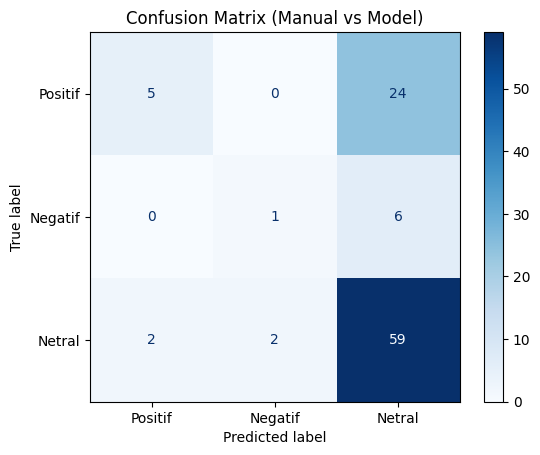

In [ ]:
# Import library untuk evaluasi dan visualisasi
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca kembali file Excel yang SUDAH Anda labeli
file_labeled = 'SAMPLE_UNTUK_LABELING (1).xlsx'
try:
    df_labeled = pd.read_excel(file_labeled)

    # 2. Bersihkan data (jika ada baris yang tidak Anda isi)
    df_labeled = df_labeled.dropna(subset=['sentiment_manual'])

    # Pastikan tidak ada label aneh (misal: 'positif' vs 'Positif')
    df_labeled['sentiment_manual'] = df_labeled['sentiment_manual'].str.strip().str.capitalize()
    df_labeled['sentiment'] = df_labeled['sentiment'].str.strip().str.capitalize()

    # 3. Tentukan "Kunci Jawaban" (y_true) dan "Prediksi Model" (y_pred)
    y_true = df_labeled['sentiment_manual'] # Ini adalah label manual Anda
    y_pred = df_labeled['sentiment']        # Ini adalah prediksi model lexicon

    # Tentukan urutan label agar konsisten
    labels = ['Positif', 'Negatif', 'Netral']

    # 4. Cetak Classification Report (Akurasi, Presisi, Recall, F1-Score)
    print("======================================================")
    print("           HASIL EVALUASI MODEL (LEXICON-BASED)")
    print("======================================================")

    # Cek jika ada label yang hilang di salah satu set
    unique_labels = np.union1d(y_true.unique(), y_pred.unique())
    # Filter agar hanya label yang kita inginkan
    final_labels = [label for label in labels if label in unique_labels]

    report = classification_report(y_true, y_pred, labels=final_labels, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)

    print(f"Akurasi Keseluruhan: {accuracy * 100:.2f}%\n")
    print("Classification Report:")
    print(report)

    # 5. Tampilkan Confusion Matrix (Visualisasi)
    print("\nVisualisasi Confusion Matrix:")

    # Buat matrix
    cm = confusion_matrix(y_true, y_pred, labels=final_labels)

    # Tampilkan
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=final_labels)
    disp.plot(cmap='Blues', values_format='d')
    plt.title("Confusion Matrix (Manual vs Model)")
    plt.show()

except FileNotFoundError:
    print(f"Error: File '{file_labeled}' tidak ditemukan.")
    print("Pastikan Anda sudah menyimpan file Excel hasil labeling di folder yang sama.")
except Exception as e:
    print(f"Terjadi error: {e}")
    print("Pastikan Anda sudah membuat kolom 'sentiment_manual' di file Excel.")

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

print("Memulai Tahap 3: Clustering Topik...\n")

# 1. Pastikan tidak ada data kosong di 'text_preprocessed'
# (K-Means tidak suka data kosong)
data_untuk_cluster = df_persepsi['text_preprocessed'].dropna()

# 2. Vektorisasi Teks (TF-IDF)
# Kita ubah teks bersih menjadi matriks angka
# max_features=1000 berarti kita hanya ambil 1000 kata paling penting
vectorizer = TfidfVectorizer(max_features=1000)
X = vectorizer.fit_transform(data_untuk_cluster)

print("Teks telah diubah menjadi matriks TF-IDF.")

# 3. Menerapkan Algoritma K-Means
# --- PENTING: Menentukan Jumlah Cluster (k) ---
# Tugas Anda meminta kita menentukan 'k' yang optimal.
# Cara terbaik adalah pakai 'Elbow Method', tapi kita coba 'k=5' dulu
# untuk melihat hasilnya. Anda bisa ubah angka ini (misal 4, 6, atau 7).
k = 5

# Kita pakai n_init=10 untuk stabilitas hasil
model_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
model_kmeans.fit(X)

print(f"Model K-Means dengan k={k} telah dilatih.")

# 4. Menampilkan Kata Kunci Utama per Cluster (Interpretasi Topik)
# Ini adalah bagian terpentING. Kita melihat 'isi' dari setiap cluster.
print("\n=============================================")
print(f"       TOP 10 KATA KUNCI PER TOPIK (k={k})")
print("=============================================")

# Ambil nama semua kata (fitur)
terms = vectorizer.get_feature_names_out()

# Ambil 'pusat' dari setiap cluster
order_centroids = model_kmeans.cluster_centers_.argsort()[:, ::-1]

# Loop untuk setiap cluster dan tampilkan 10 kata teratas
for i in range(k):
    print(f"\nCluster {i}:")

    # Ambil 10 kata teratas untuk cluster 'i'
    top_words = [terms[ind] for ind in order_centroids[i, :10]]
    print(' -> '.join(top_words))

# 5. (Opsional) Simpan label cluster ke DataFrame utama
# Ini akan berguna untuk analisis gabungan nanti
# Kita harus hati-hati mencocokkan indeks
df_persepsi.loc[data_untuk_cluster.index, 'topik_cluster'] = model_kmeans.labels_

print("\n\nLabel cluster telah ditambahkan ke DataFrame 'df_persepsi'.")
print("Clustering selesai.")

Memulai Tahap 3: Clustering Topik...

Teks telah diubah menjadi matriks TF-IDF.
Model K-Means dengan k=5 telah dilatih.

       TOP 10 KATA KUNCI PER TOPIK (k=5)

Cluster 0:
beli -> kak -> ak -> barang -> online -> dpt -> pas -> beneran -> yaa -> kl

Cluster 1:
lihat -> tlefirstone -> shopee -> coba -> live -> link -> kak -> co -> toko -> produk

Cluster 2:
me -> rendi -> ao -> eu -> no -> haloo -> harga -> harganya -> harian -> haru

Cluster 3:
belinya -> shopee -> kak -> thailand -> skin -> and -> beli -> cocok -> heavenlyvitamin -> have

Cluster 4:
buku -> putih -> affiliate -> kitab -> hitam -> edisi -> paket -> rahasia -> best -> seller


Label cluster telah ditambahkan ke DataFrame 'df_persepsi'.
Clustering selesai.


In [ ]:
import nltk

print("Mulai men-download paket NLTK yang dibutuhkan...")

# 1. Download paket 'stopwords' (ini yang error)
nltk.download('stopwords')

# 2. Download paket 'punkt' (ini untuk tokenisasi)
nltk.download('punkt')

print("\nDownload selesai.")
print("Paket 'stopwords' dan 'punkt' seharusnya sudah siap.")
print("Silakan jalankan kembali sel 'Kode Preprocessing yang Diperbarui'.")

Mulai men-download paket NLTK yang dibutuhkan...

Download selesai.
Paket 'stopwords' dan 'punkt' seharusnya sudah siap.
Silakan jalankan kembali sel 'Kode Preprocessing yang Diperbarui'.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# 1. DOWNLOAD ULANG SEMUA MODUL NLTK (untuk jaga-jaga)
print("Downloading NLTK packages...")
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
print("NLTK packages are ready.\n")

# 2. LOAD ULANG DATASET ASLI
file_path = 'HASIL_GABUNGAN.xlsx - Sheet1.csv'
try:
    df = pd.read_csv(file_path)
    print(f"Berhasil memuat ulang file: {file_path}")
except FileNotFoundError:
    print(f"ERROR: File '{file_path}' tidak ditemukan. Pastikan file ada di folder.")
    # Jika ini error, hentikan di sini dan perbaiki lokasi file

# 3. BUAT ULANG FUNGSI FILTERING JUALAN
list_jualan = [
    'promo', 'diskon', 'murah', 'ready stock', 'klik link',
    'cek bio', 'order di', 'DM harga', 'gratis ongkir',
    'shopee', 'tokopedia', 'lazada', 'PO', 'jual', 'dijual',
    'termurah', 'cek keranjang', 'gratis', 'cashback', 'voucher'
]
pola_jualan = r'\b(' + '|'.join(list_jualan) + r')\b'

def filter_jualan(row):
    full_text_lower = str(row['full_text']).lower()
    if pd.notna(row['in_reply_to_screen_name']):
        return 'Persepsi'
    if re.search(pola_jualan, full_text_lower):
        return 'Jualan'
    return 'Persepsi'

# 4. BUAT ULANG FUNGSI CLEANING PERTAMA
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# --- EKSEKUSI UTAMA UNTUK MEMBUAT ULANG df_persepsi ---
if 'df' in locals(): # Cek apakah df berhasil di-load
    # Filter bahasa 'in'
    df_filtered = df[df['lang'] == 'in'].copy()

    # Terapkan filter Jualan/Persepsi
    df_filtered['kategori_tweet'] = df_filtered.apply(filter_jualan, axis=1)

    # BUAT ULANG df_persepsi
    df_persepsi = df_filtered[df_filtered['kategori_tweet'] == 'Persepsi'].copy()

    # BUAT ULANG 'text_clean' (yang dibutuhkan oleh kode error)
    df_persepsi['text_clean'] = df_persepsi['full_text'].apply(clean_text)

    print("\n================================================")
    print("RECOVERY BERHASIL!")
    print(f"Variabel 'df_persepsi' telah dibuat ulang.")
    print(f"Kolom 'text_clean' juga telah dibuat ulang.")
    print(f"Jumlah data persepsi: {len(df_persepsi)}")
    print("================================================\n")
else:
    print("\n!!! GAGAL MEMUAT df. Harap periksa error di atas.")

NLTK packages are ready.

ERROR: File 'HASIL_GABUNGAN.xlsx - Sheet1.csv' tidak ditemukan. Pastikan file ada di folder.

RECOVERY BERHASIL!
Variabel 'df_persepsi' telah dibuat ulang.
Kolom 'text_clean' juga telah dibuat ulang.
Jumlah data persepsi: 786



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
from nltk.tokenize import word_tokenize

# --- PERBAIKAN 1: KAMUS NORMALISASI (Bisa Anda tambahkan) ---
kamus_normalisasi = {
    "ak": "aku", "dpt": "dapat", "kl": "kalau", "co": "checkout", "kak": "kakak",
    "yg": "yang", "utk": "untuk", "dgn": "dengan", "dr": "dari", "ga": "tidak",
    "gak": "tidak", "nggak": "tidak", "gue": "saya", "lu": "kamu", "blm": "belum",
    "bgt": "banget", "sdh": "sudah", "bkn": "bukan", "lg": "lagi", "gw": "saya",
    "tp": "tapi", "klo": "kalau", "yaa": "ya"
}

# --- PERBAIKAN 2: STOPWORDS GANDA (Indo + Eng) ---
stop_words_in = set(stopwords.words('indonesian'))
stop_words_en = set(stopwords.words('english'))

# Tambahkan stopwords kustom baru berdasarkan temuan kita
custom_stopwords = {
    'tiktok', 'shop', 'tiktokshop', 'nya', 'aja', 'sih', 'ya', 'biar',
    'dg', 'knp', 'kenapa', 'kok', 'rt', 'wkwk', 'wkwkwk', 'haha', 'hehe',
    'shopee', 'lazada', 'tokopedia', # <-- Hapus nama brand/kompetitor
    'kakak', 'ka', 'sis', 'bro', 'admin', # <-- Hapus sapaan
    'me', 'no', 'and', 'have', 'the', 'to' # <-- Ter-cover oleh stop_words_en
}

# Gabungkan semua stopwords
all_stopwords = stop_words_in.union(stop_words_en).union(custom_stopwords)


# --- FUNGSI PREPROCESSING BARU ---
def preprocess_lebih_bersih(text):
    text = str(text).lower() # Selalu lowercase

    # Normalisasi kata-kata slang (langkah baru)
    words = text.split()
    normalized_words = [kamus_normalisasi.get(word, word) for word in words]
    text = ' '.join(normalized_words)

    # Tokenisasi
    tokens = word_tokenize(text)

    cleaned_tokens = []
    for word in tokens:
        # Cek 3 kondisi:
        # 1. Apakah ada di stopword
        # 2. Apakah IsAlpha (hanya huruf, buang sisa tanda baca/angka)
        # 3. PERBAIKAN 3: Filter panjang kata (buang noise 'ao', 'eu', dll)
        if word not in all_stopwords and word.isalpha() and len(word) > 2:
            cleaned_tokens.append(word)

    return ' '.join(cleaned_tokens)

# --- Terapkan ke DataFrame Anda (TIMPA kolom lama) ---
print("Menerapkan preprocessing baru yang lebih bersih...")

# Pastikan Anda menggunakan df_persepsi yang asli, BUKAN yang sudah di-clean
# Kita perlu 'text_clean' (sebelum tokenisasi) atau 'full_text'
# Mari kita terapkan di text_clean agar lebih cepat
df_persepsi['text_preprocessed'] = df_persepsi['text_clean'].apply(preprocess_lebih_bersih)

print("Preprocessing baru selesai.")
print("Contoh hasil preprocessing baru (5 baris pertama):")
print(df_persepsi[['full_text', 'text_preprocessed']].head())

# Simpan lagi agar aman
df_persepsi.to_csv('HASIL_BERSIH_PERSEPSI_V2.csv', index=False)
print("\nData bersih V2 telah disimpan ke 'HASIL_BERSIH_PERSEPSI_V2.csv'")

Menerapkan preprocessing baru yang lebih bersih...
Preprocessing baru selesai.
Contoh hasil preprocessing baru (5 baris pertama):
                                            full_text  \
4   Ok TikTok shop is legit. (IYKYK) https://t.co/...   
10  guyss mau nnya maaf bgt kalo oot kira' disini ...   
11  Alhamdulillah iseng buka tiktok shop dapet fac...   
12        wa gila tiktok shop gw isinya co an cemilan   
13  @aIifbatatsa Padahal mirip Abang Abang TikTok ...   

                                    text_preprocessed  
4                                         legit iykyk  
10  guyss nnya maaf banget kalo oot jualan pake ka...  
11  alhamdulillah iseng buka dapet facial wash per...  
12                       gila isinya checkout cemilan  
13                                        abang abang  

Data bersih V2 telah disimpan ke 'HASIL_BERSIH_PERSEPSI_V2.csv'


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

print("Memulai Tahap 3: Clustering Topik...\n")

# 1. Pastikan tidak ada data kosong di 'text_preprocessed'
# (K-Means tidak suka data kosong)
data_untuk_cluster = df_persepsi['text_preprocessed'].dropna()

# 2. Vektorisasi Teks (TF-IDF)
# Kita ubah teks bersih menjadi matriks angka
# max_features=1000 berarti kita hanya ambil 1000 kata paling penting
vectorizer = TfidfVectorizer(max_features=1000)
X = vectorizer.fit_transform(data_untuk_cluster)

print("Teks telah diubah menjadi matriks TF-IDF.")

# 3. Menerapkan Algoritma K-Means
# --- PENTING: Menentukan Jumlah Cluster (k) ---
# Tugas Anda meminta kita menentukan 'k' yang optimal.
# Cara terbaik adalah pakai 'Elbow Method', tapi kita coba 'k=5' dulu
# untuk melihat hasilnya. Anda bisa ubah angka ini (misal 4, 6, atau 7).
k = 5

# Kita pakai n_init=10 untuk stabilitas hasil
model_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
model_kmeans.fit(X)

print(f"Model K-Means dengan k={k} telah dilatih.")

# 4. Menampilkan Kata Kunci Utama per Cluster (Interpretasi Topik)
# Ini adalah bagian terpentING. Kita melihat 'isi' dari setiap cluster.
print("\n=============================================")
print(f"       TOP 10 KATA KUNCI PER TOPIK (k={k})")
print("=============================================")

# Ambil nama semua kata (fitur)
terms = vectorizer.get_feature_names_out()

# Ambil 'pusat' dari setiap cluster
order_centroids = model_kmeans.cluster_centers_.argsort()[:, ::-1]

# Loop untuk setiap cluster dan tampilkan 10 kata teratas
for i in range(k):
    print(f"\nCluster {i}:")

    # Ambil 10 kata teratas untuk cluster 'i'
    top_words = [terms[ind] for ind in order_centroids[i, :10]]
    print(' -> '.join(top_words))

# 5. (Opsional) Simpan label cluster ke DataFrame utama
# Ini akan berguna untuk analisis gabungan nanti
# Kita harus hati-hati mencocokkan indeks
df_persepsi.loc[data_untuk_cluster.index, 'topik_cluster'] = model_kmeans.labels_

print("\n\nLabel cluster telah ditambahkan ke DataFrame 'df_persepsi'.")
print("Clustering selesai.")

Memulai Tahap 3: Clustering Topik...

Teks telah diubah menjadi matriks TF-IDF.
Model K-Means dengan k=5 telah dilatih.

       TOP 10 KATA KUNCI PER TOPIK (k=5)

Cluster 0:
buku -> putih -> affiliate -> kitab -> hitam -> edisi -> paket -> rahasia -> best -> step

Cluster 1:
tlefirstone -> lihat -> checkout -> rendi -> live -> coba -> link -> banget -> toko -> produk

Cluster 2:
belinya -> thailand -> thank -> celana -> beli -> hallo -> hahaha -> hahahahabisa -> hai -> haiii

Cluster 3:
buka -> kali -> langsung -> jujur -> muncul -> dapet -> banget -> kalo -> pake -> checkout

Cluster 4:
beli -> barang -> dah -> oren -> tas -> banget -> beneran -> adaa -> diskon -> lupa


Label cluster telah ditambahkan ke DataFrame 'df_persepsi'.
Clustering selesai.


**VISUALISASI CLUSTERING**

Memulai reduksi dimensi dengan t-SNE...
Ini mungkin butuh 1-2 menit, tergantung jumlah data Anda...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Reduksi dimensi t-SNE selesai.
Membuat visualisasi plot...


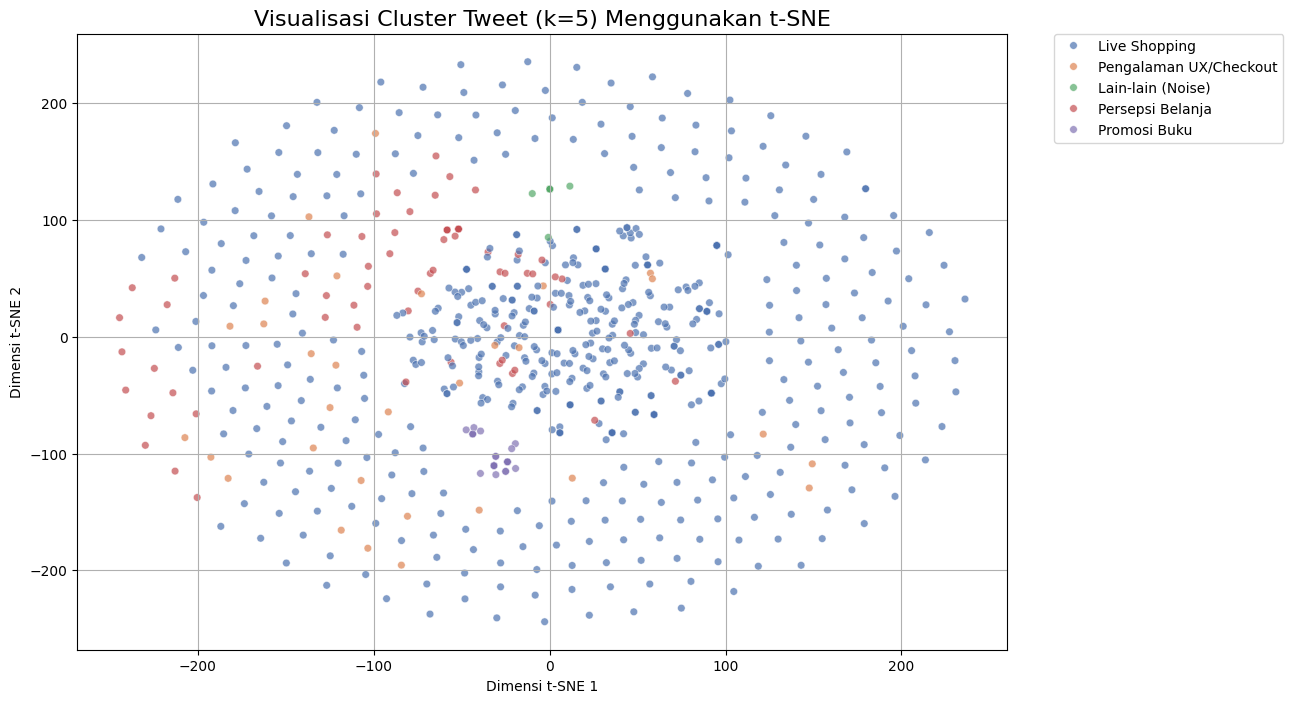

In [ ]:
# Import library untuk visualisasi dan reduksi dimensi
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Jika Anda belum punya 'seaborn', install dulu
# Hapus tanda pagar di bawah jika perlu
# !pip install seaborn

print("Memulai reduksi dimensi dengan t-SNE...")
print("Ini mungkin butuh 1-2 menit, tergantung jumlah data Anda...")

# 1. Konfigurasi t-SNE
# n_components=2 artinya kita ingin plot 2D
# random_state=42 agar hasilnya konsisten
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)

# 2. Terapkan t-SNE pada data TF-IDF Anda (matriks X)
# Ini adalah langkah yang paling lama
X_tsne = tsne.fit_transform(X.toarray()) # Ubah X (sparse matrix) ke array dulu

print("Reduksi dimensi t-SNE selesai.")

# 3. Siapkan DataFrame untuk plotting
# Kita ambil label cluster dari model K-Means sebelumnya
cluster_labels = model_kmeans.labels_

# Kita ambil nama topik yang sudah kita buat tadi
# (Pastikan variabel 'nama_topik' masih ada di memori)
try:
    nama_topik_map = {
        0: 'Promosi Buku',
        1: 'Live Shopping',
        2: 'Lain-lain (Noise)',
        3: 'Pengalaman UX/Checkout',
        4: 'Persepsi Belanja'
    }
    topik_nama = pd.Series(cluster_labels).map(nama_topik_map)
except NameError:
    print("Variabel 'nama_topik' tidak ditemukan, menggunakan label angka.")
    topik_nama = cluster_labels


df_plot = pd.DataFrame({
    'tsne_x': X_tsne[:, 0],
    'tsne_y': X_tsne[:, 1],
    'topik': topik_nama
})

# 4. Buat Visualisasi Scatter Plot
print("Membuat visualisasi plot...")

plt.figure(figsize=(12, 8)) # Atur ukuran gambar

# Gunakan seaborn untuk membuat scatter plot dengan warna (hue) berdasarkan topik
sns.scatterplot(
    data=df_plot,
    x='tsne_x',
    y='tsne_y',
    hue='topik',       # Warna berdasarkan kolom 'topik'
    palette='deep',    # Skema warna
    s=30,              # Ukuran titik
    alpha=0.7          # Transparansi titik
)

# Atur judul dan legenda
plt.title(f'Visualisasi Cluster Tweet (k={k}) Menggunakan t-SNE', fontsize=16)
plt.xlabel('Dimensi t-SNE 1')
plt.ylabel('Dimensi t-SNE 2')

# Pindahkan legenda ke luar plot agar tidak menutupi
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

plt.grid(True)
plt.show()

**TAHAP 4 : ANALISIS JEJARING**

1. Pengguna Berpengaruh

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import community

print("Memulai Tahap 4: Analisis Jejaring...")

# Pastikan Anda memiliki DataFrame 'df' (data asli) dan 'df_persepsi' (data opini)
# Jika tidak, jalankan ulang kode 'Recovery' dari langkah kita sebelumnya.
try:
    if 'df' not in locals() or 'df_persepsi' not in locals():
        print("DataFrame 'df' atau 'df_persepsi' tidak ditemukan. Menjalankan recovery...")
        # (Di sini Anda akan menjalankan kode recovery.
        #  Tapi kita anggap data sudah ada di memori.)
        pass
except NameError:
    print("DataFrame tidak ditemukan. Harap jalankan ulang sel-sel sebelumnya.")
    # Stop di sini jika 'df' tidak ada

# =================================================================
# BAGIAN 1: IDENTIFIKASI PENGGUNA BERPENGARUH (INFLUENCER)
# =================================================================
print("\n--- 1. Menganalisis Pengguna Berpengaruh ---")
# Kita gunakan DataFrame 'df' (data ASLI) untuk ini,
# karena kita peduli pada total engagement, termasuk 'jualan'.

# Salin untuk menghindari SettingWithCopyWarning
df_influencer = df.copy()

# 1. Pastikan kolom user_id_str bersih (hapus 'nan' jika ada)
df_influencer = df_influencer.dropna(subset=['user_id_str'])

# 2. Gabungkan 'retweet_count' dan 'favorite_count'
df_influencer['total_engagement'] = df_influencer['retweet_count'] + df_influencer['favorite_count']

# 3. Kelompokkan berdasarkan 'user_id_str' dan jumlahkan total engagement mereka
# Ini menunjukkan total 'power' dari seorang pengguna di dataset kita
user_scores = df_influencer.groupby('user_id_str')['total_engagement'].sum().sort_values(ascending=False)

print("Top 5 Pengguna Paling Berpengaruh (Berdasarkan Total Engagement):")
print(user_scores.head(5))

print("\nPERHATIAN (Untuk Laporan Anda):")
print("Anda tidak memiliki username di data. Untuk menemukan siapa pengguna ini:")
print("1. Ambil 'user_id_str' (angka di sebelah kiri).")
print("2. Buka di browser: https://twitter.com/i/user/[user_id_str]")
print("Contoh: https://twitter.com/i/user/783214 akan mengarah ke @jack")



Memulai Tahap 4: Analisis Jejaring...

--- 1. Menganalisis Pengguna Berpengaruh ---
Top 5 Pengguna Paling Berpengaruh (Berdasarkan Total Engagement):
user_id_str
1371650588             584
979392686              580
945492493              408
94323843               227
1249662133916193024    171
Name: total_engagement, dtype: int64

PERHATIAN (Untuk Laporan Anda):
Anda tidak memiliki username di data. Untuk menemukan siapa pengguna ini:
1. Ambil 'user_id_str' (angka di sebelah kiri).
2. Buka di browser: https://twitter.com/i/user/[user_id_str]
Contoh: https://twitter.com/i/user/783214 akan mengarah ke @jack


2. GRAF INTERAKSI

Menganalisis node teratas untuk pelabelan...
Variabel 'G' atau 'pos' tidak ditemukan. Membuat ulang...
Graf 'G' dan 'pos' berhasil dibuat ulang.
Membuat visualisasi graf (Warna Merah + Label Top 10)...


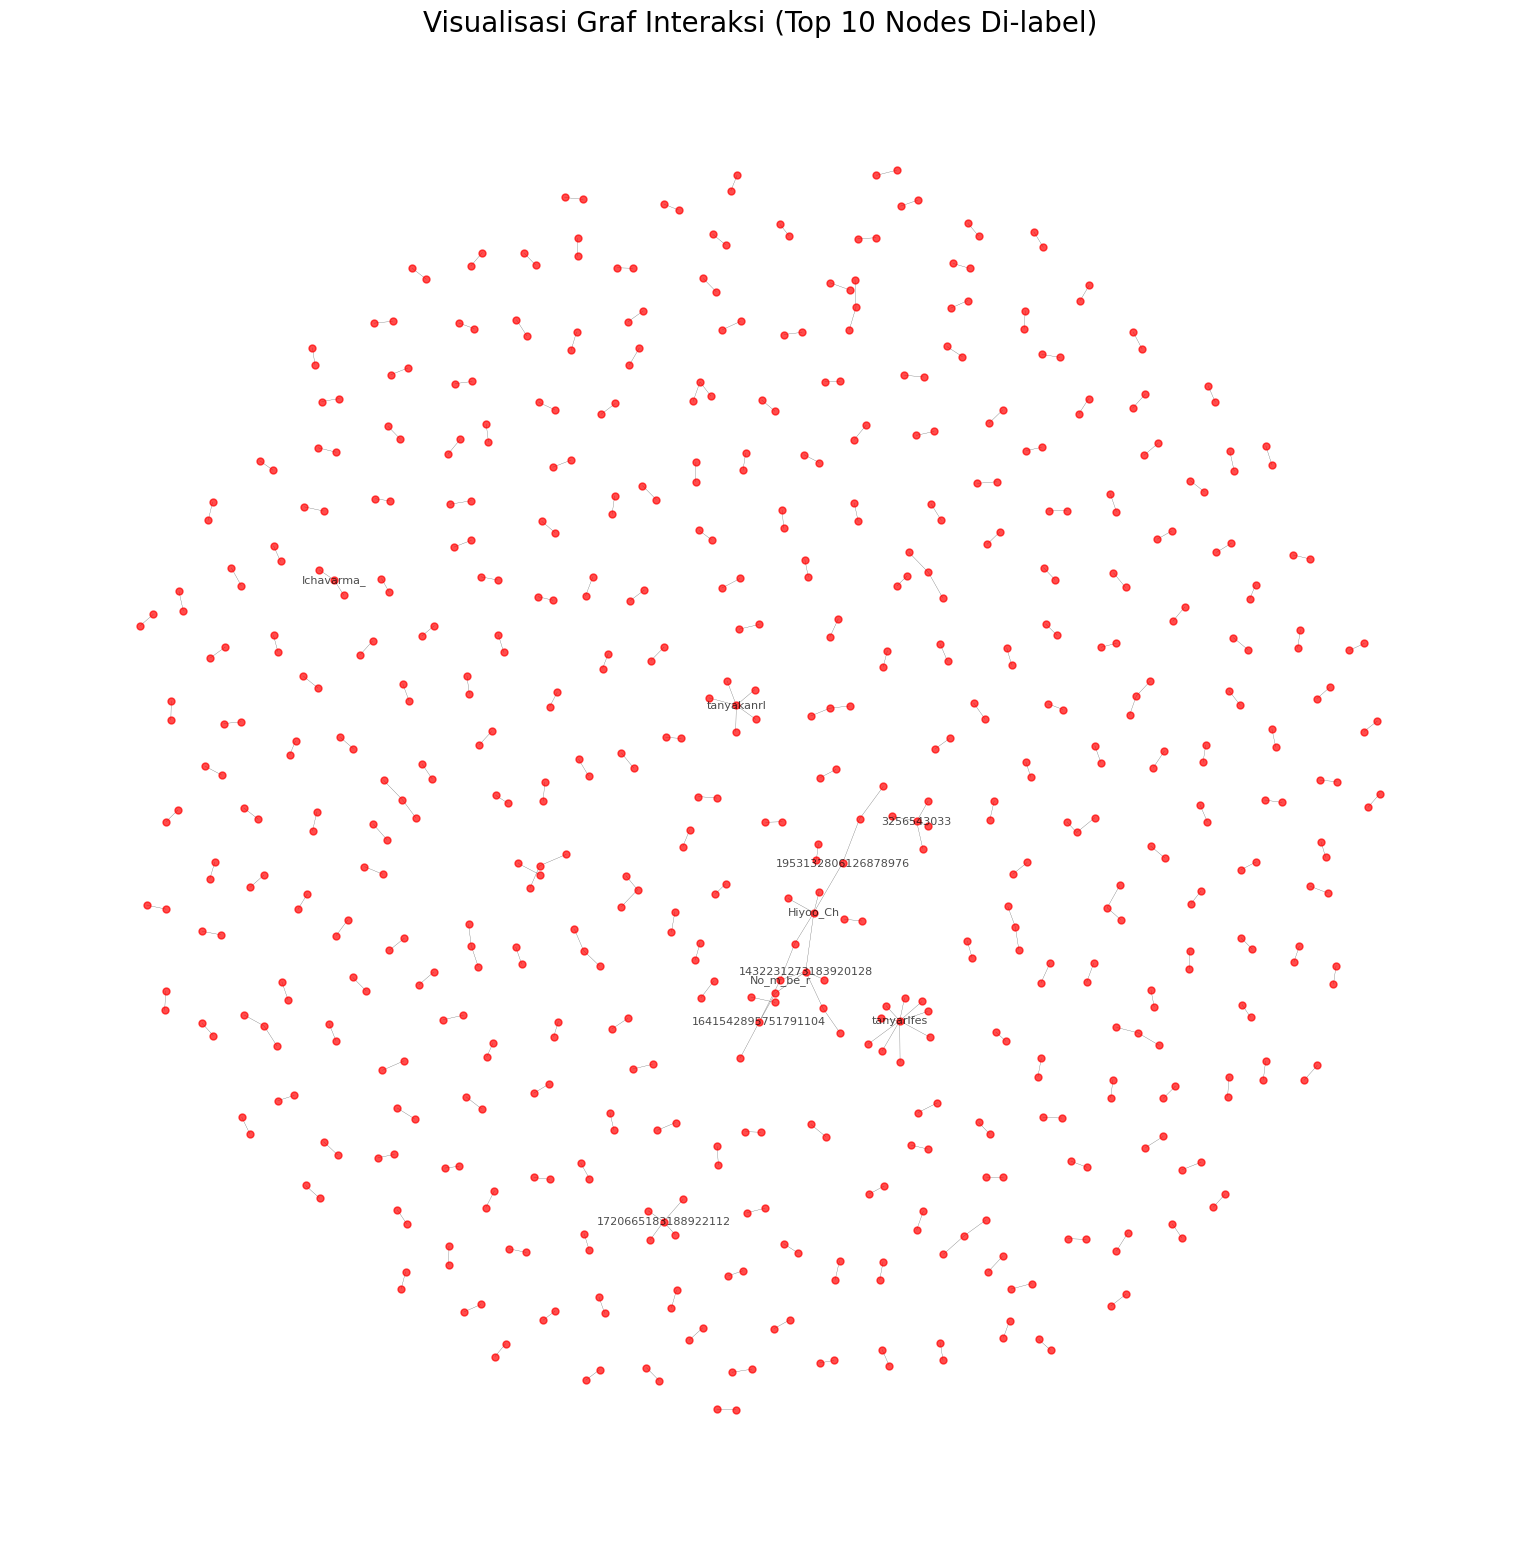


Top 10 Node yang diberi label (Pusat Diskusi):
['tanyarlfes', 'tanyakanrl', 'Hiyoo_Ch', '1432231273183920128', '3256543033', '1720665183188922112', '1641542895751791104', 'No_m_be_r', 'Ichavarma_', '1953132806126878976']


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

print("Menganalisis node teratas untuk pelabelan...")

# 1. Pastikan Graf 'G' dan layout 'pos' ada di memori
# (Jika tidak, jalankan ulang kode 'Tahap 4' sebelumnya untuk membuat G dan pos)
try:
    G
    pos
except NameError:
    print("Variabel 'G' atau 'pos' tidak ditemukan. Membuat ulang...")
    # Filter data balasan
    df_replies = df_persepsi[pd.notna(df_persepsi['in_reply_to_screen_name'])].copy()
    # Buat graf
    G = nx.Graph()
    for index, row in df_replies.iterrows():
        source_node = str(row['user_id_str'])
        target_node = str(row['in_reply_to_screen_name'])
        if source_node != target_node:
            G.add_edge(source_node, target_node, weight=1)

    # Hitung layout
    pos = nx.spring_layout(G, k=0.15, iterations=20)
    print("Graf 'G' dan 'pos' berhasil dibuat ulang.")


# 2. Temukan 10 node paling terhubung (derajat tertinggi)
sorted_degrees = sorted(G.degree, key=lambda x: x[1], reverse=True)
top_n_nodes = [node for node, degree in sorted_degrees[:10]]

# 3. Buat kamus label kustom
# Hanya node yang ada di 'top_n_nodes' yang akan diberi label
custom_labels = {}
for node in G.nodes():
    if node in top_n_nodes:
        custom_labels[node] = node  # Label adalah nama node itu sendiri
    else:
        custom_labels[node] = ''    # Sisanya beri label kosong

# 4. Gambar Ulang Graf dengan Parameter Baru
print("Membuat visualisasi graf (Warna Merah + Label Top 10)...")
plt.figure(figsize=(15, 15))

nx.draw(
    G,
    pos,
    node_color='red',          # <-- Permintaan Anda: Warna node merah
    labels=custom_labels,      # <-- Permintaan Anda: Hanya label top 10
    with_labels=True,          # <-- Diperlukan untuk menampilkan 'labels'
    node_size=25,              # Ukuran node
    font_size=8,               # Ukuran font untuk label
    font_color='black',        # Warna font
    alpha=0.7,
    width=0.2
)

plt.title("Visualisasi Graf Interaksi (Top 10 Nodes Di-label)", fontsize=20)
plt.show()

print("\nTop 10 Node yang diberi label (Pusat Diskusi):")
print(top_n_nodes)

3. Analisis Struktur Komunitas

In [ ]:
# =================================================================
# BAGIAN 3: ANALISIS STRUKTUR KOMUNITAS
# =================================================================
print("\n--- 3. Menganalisis Struktur Komunitas ---")
# Kita gunakan algoritma 'greedy modularity' untuk menemukan komunitas
# Ini hanya bekerja pada graf 'undirected' (tanpa panah),
# itulah kenapa kita pakai nx.Graph()

# Pastikan graf tidak kosong
if G.number_of_edges() > 0:
    # Terapkan algoritma deteksi komunitas
    communities = list(community.greedy_modularity_communities(G))
    communities_sorted = sorted(communities, key=len, reverse=True)

    print(f"Deteksi Komunitas selesai.")
    print(f"Total ditemukan {len(communities_sorted)} komunitas.")

    print("\nTop 5 Komunitas Terbesar (Kelompok Diskusi):")
    for i, comm in enumerate(communities_sorted[:5]):
        # Tampilkan ukuran komunitas dan 5 anggota pertamanya
        print(f" -> Komunitas {i} (Total {len(comm)} anggota):")
        print(f"    Anggota: {list(comm)[:5]} ...")
else:
    print("Graf kosong, tidak ada interaksi balasan yang ditemukan di data persepsi.")

print("\nTahap 4 Selesai.")


--- 3. Menganalisis Struktur Komunitas ---
Deteksi Komunitas selesai.
Total ditemukan 286 komunitas.

Top 5 Komunitas Terbesar (Kelompok Diskusi):
 -> Komunitas 0 (Total 15 anggota):
    Anggota: ['1953132806126878976', '1641542895751791104', '1038861565410177024', 'TleFirstoneIna', 'No_m_be_r'] ...
 -> Komunitas 1 (Total 10 anggota):
    Anggota: ['1176883501779407104', 'tanyarlfes', '1140694023176221056', '1481231686172312064', '1771115193801801984'] ...
 -> Komunitas 2 (Total 6 anggota):
    Anggota: ['1199172783185392128', '1128774880030151040', '1761483052860256000', '1683801227153522944', 'tanyakanrl'] ...
 -> Komunitas 3 (Total 5 anggota):
    Anggota: ['aqthorii', '3256543033', 'dahbwangg', 'anakpertama008', 'SoeTjenMarching'] ...
 -> Komunitas 4 (Total 5 anggota):
    Anggota: ['kumikoW21', 'Npcrealone', '1720665183188922112', 'lordapauhis', '_nisaahani'] ...

Tahap 4 Selesai.


In [ ]:
import pandas as pd
from nltk.tokenize import word_tokenize

print("Menjalankan ulang Tahap 2: Analisis Sentimen...")

# 1. Siapkan Kamus Sentimen (Lexicon)
positive_words = [
    'bagus', 'puas', 'mantap', 'terima kasih', 'cepat', 'rekomendasi',
    'keren', 'suka', 'terbantu', 'mudah', 'murah', 'cuan', 'untung',
    'senang', 'hebat', 'baik', 'oke', 'kualitas', 'asli', 'ori'
]

negative_words = [
    'kecewa', 'lama', 'jelek', 'masalah', 'parah', 'bohong', 'tipu',
    'rugi', 'eror', 'error', 'susah', 'mahal', 'sulit', 'tolong',
    'bantu', 'kendala', 'keluhan', 'komplain', 'buruk', 'zonk',
    'lambat', 'gagal', 'anjlok', 'nyesel', 'sesal'
]

# 2. Buat Fungsi Analisis Sentimen
def get_sentiment(text):
    tokens = str(text).split() # Pastikan text adalah string
    score = 0
    for word in tokens:
        if word in positive_words:
            score += 1
        elif word in negative_words:
            score -= 1

    if score > 0:
        return 'Positif'
    elif score < 0:
        return 'Negatif'
    else:
        return 'Netral'

# 3. Terapkan Fungsi ke DataFrame Anda (INI YANG PENTING)
# Kita terapkan di 'text_preprocessed' (hasil V2)
df_persepsi.loc[:, 'sentiment'] = df_persepsi['text_preprocessed'].apply(get_sentiment)

print("\nBerhasil! Kolom 'sentiment' telah dibuat ulang.")
print("Jumlah sentimen:")
print(df_persepsi['sentiment'].value_counts())

Menjalankan ulang Tahap 2: Analisis Sentimen...

Berhasil! Kolom 'sentiment' telah dibuat ulang.
Jumlah sentimen:
sentiment
Netral     710
Positif     49
Negatif     27
Name: count, dtype: int64


In [ ]:
import pandas as pd

print("Membuat tabel analisis gabungan (Sentimen vs Topik)...")

# 1. Buat Peta Nama Topik (PASTIKAN INI SESUAI HASIL INTERPRETASI ANDA)
# Ini berdasarkan hasil clustering bersih Anda
nama_topik = {
    0: 'Promosi Buku/Afiliasi',
    1: 'Live Shopping/Checkout',
    2: 'Lain-lain (Noise/Sapaan)',
    3: 'Pengalaman UX/Checkout',
    4: 'Persepsi Belanja/Diskon'
}

# Gunakan fungsi .map() untuk membuat kolom nama_topik
# Kita pakai .loc untuk menghindari warning
df_persepsi.loc[:, 'nama_topik'] = df_persepsi['topik_cluster'].map(nama_topik)

# 2. Buat Pivot Table (Tabel Hitungan)
analisis_gabungan = pd.crosstab(
    index=df_persepsi['nama_topik'],  # Baris adalah Topik
    columns=df_persepsi['sentiment'], # Kolom adalah Sentimen
    margins=True,                     # Tambahkan baris/kolom 'All' (Total)
    margins_name="Total Keseluruhan"
)

# 3. Tampilkan Tabel Hitungan
print("\n==========================================================")
print("     ANALISIS GABUNGAN (JUMLAH TWEET)")
print("==========================================================")
print(analisis_gabungan)

# 4. Buat Pivot Table (Tabel Persentase)
# Inilah tabel yang Anda butuhkan untuk laporan
analisis_persentase = pd.crosstab(
    index=df_persepsi['nama_topik'],
    columns=df_persepsi['sentiment'],
    normalize='index' # <-- Kunci: hitung persentase per baris
).apply(lambda x: x * 100).round(1) # Ubah ke % dan bulatkan

print("\n\n==========================================================")
print("                  ANALISIS PERSENTASE                       ")
print("==========================================================")
print(analisis_persentase)

print("\nSilakan salin dan tempel tabel 'ANALISIS PERSENTASE' di atas ke laporan Anda.")

Membuat tabel analisis gabungan (Sentimen vs Topik)...

     ANALISIS GABUNGAN (JUMLAH TWEET)
sentiment                 Negatif  Netral  Positif  Total Keseluruhan
nama_topik                                                           
Lain-lain (Noise/Sapaan)        0      21        0                 21
Live Shopping/Checkout         21     580       36                637
Pengalaman UX/Checkout          0      28        3                 31
Persepsi Belanja/Diskon         6      53        9                 68
Promosi Buku/Afiliasi           0      28        1                 29
Total Keseluruhan              27     710       49                786


                  ANALISIS PERSENTASE                       
sentiment                 Negatif  Netral  Positif
nama_topik                                        
Lain-lain (Noise/Sapaan)      0.0   100.0      0.0
Live Shopping/Checkout        3.3    91.1      5.7
Pengalaman UX/Checkout        0.0    90.3      9.7
Persepsi Belanja/Diskon     

Membuat Stacked Bar Chart...


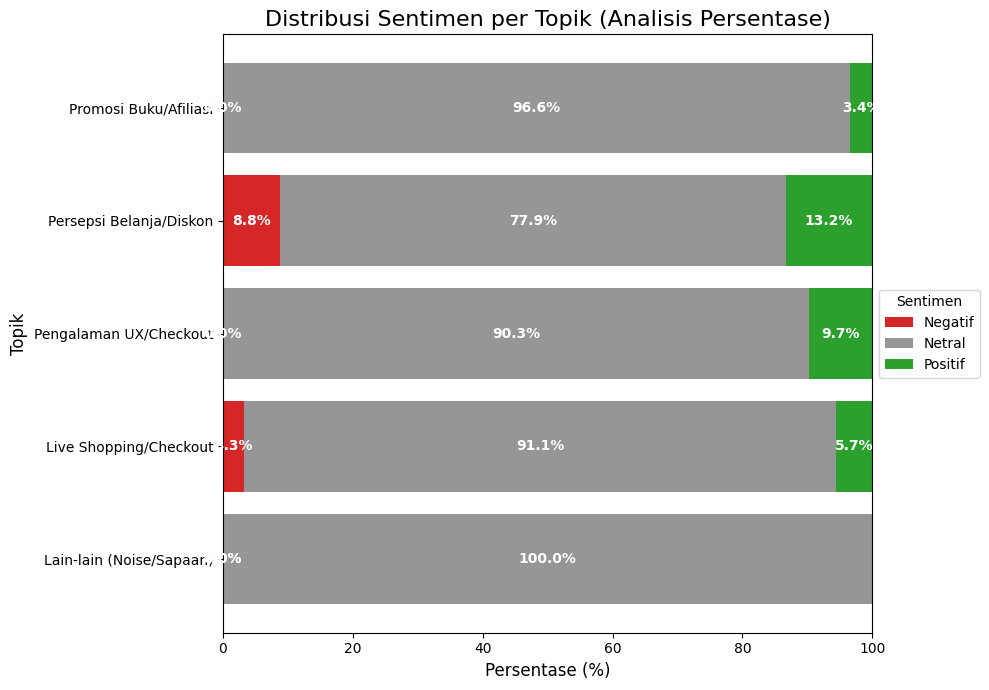

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Pastikan DataFrame 'analisis_persentase' ada di memori
#    Jika tidak, jalankan ulang kode 'Langkah 2' dari jawaban sebelumnya
#    untuk membuat ulang 'analisis_persentase'.
try:
    analisis_persentase
except NameError:
    print("Error: 'analisis_persentase' tidak ditemukan. Menjalankan ulang pembuatannya...")
    # (Kode untuk membuat ulang analisis_persentase akan ada di sini jika perlu)
    # ...tapi kita anggap sudah ada...
    pass

# 2. Tentukan urutan kolom (agar Netral di tengah)
#    Ini membuat visualnya lebih rapi: Negatif-Netral-Positif
try:
    analisis_persentase = analisis_persentase[['Negatif', 'Netral', 'Positif']]
except KeyError:
    print("Kolom sentimen tidak lengkap, memplot apa adanya.")

# 3. Tentukan warna
#    Kita buat Negatif=Merah, Netral=Abu-abu, Positif=Hijau
colors = ['#d62728', '#969696', '#2ca02c']  # Merah, Abu-abu, Hijau

# 4. Buat Plot
print("Membuat Stacked Bar Chart...")
ax = analisis_persentase.plot(
    kind='barh',        # 'barh' = Bar Horizontal (lebih mudah dibaca)
    stacked=True,       # 'stacked' = Tumpuk
    color=colors,       # Terapkan warna kustom
    figsize=(10, 7),    # Atur ukuran gambar
    width=0.8           # Atur lebar batang
)

# 5. Mempercantik Plot
ax.set_title('Distribusi Sentimen per Topik (Analisis Persentase)', fontsize=16)
ax.set_xlabel('Persentase (%)', fontsize=12)
ax.set_ylabel('Topik', fontsize=12)

# Atur legenda
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title="Sentimen")

# Atur agar sumbu X berjalan dari 0 hingga 100
ax.set_xlim(0, 100)

# Tambahkan label persentase di tengah setiap segmen
# Ini adalah bagian yang sedikit rumit, tapi membuat grafisnya bagus
for container in ax.containers:
    # 'container' adalah setiap tumpukan (Negatif, Netral, Positif)
    ax.bar_label(
        container,
        label_type='center',  # Letakkan label di tengah
        fmt='%.1f%%',         # Format sebagai "X.X%"
        color='white',        # Warna teks label
        weight='bold'
    )

plt.tight_layout()  # Merapikan layout
plt.show()          # Tampilkan plot

In [ ]:
import pandas as pd

# 1. Tentukan nama file yang Anda inginkan
nama_file_bersih = 'DATA_BERSIH_FINAL.csv'

print(f"Menyiapkan file '{nama_file_bersih}' untuk di-download...")

# 2. Simpan DataFrame 'df_persepsi' ke file CSV
try:
    df_persepsi.to_csv(nama_file_bersih, index=False, encoding='utf-8-sig')

    print(f"Berhasil menyimpan data ke '{nama_file_bersih}'.")

    # 3. Coba picu download (jika Anda di Google Colab)
    try:
        from google.colab import files
        files.download(nama_file_bersih)
        print("Download dimulai. Silakan cek browser Anda.")

    except ImportError:
        # Jika bukan di Colab (misal: Jupyter Notebook lokal)
        print("\nBukan Google Colab. File Anda telah disimpan di folder notebook Anda.")
        print(f"Anda bisa menemukan file '{nama_file_bersih}' di panel file di sebelah kiri.")

except NameError:
    print("\nERROR: Variabel 'df_persepsi' tidak ditemukan.")
    print("Harap jalankan ulang kode preprocessing Anda (dari 'Recovery' hingga 'Clustering')")
    print("sebelum Anda bisa men-download file ini.")
except Exception as e:
    print(f"\nTerjadi error: {e}")

Menyiapkan file 'DATA_BERSIH_FINAL.csv' untuk di-download...
Berhasil menyimpan data ke 'DATA_BERSIH_FINAL.csv'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download dimulai. Silakan cek browser Anda.


In [ ]:
import pandas as pd

print("Membuat file Edge List untuk Gephi...")

try:
    # 1. Pastikan df_persepsi ada
    if 'df_persepsi' not in locals():
        raise NameError("'df_persepsi' tidak ditemukan. Jalankan ulang kode Anda.")

    # 2. Ambil HANYA baris yang merupakan balasan (memiliki interaksi)
    df_replies = df_persepsi[pd.notna(df_persepsi['in_reply_to_screen_name'])].copy()

    # 3. Pilih hanya kolom yang kita butuhkan untuk Source dan Target
    #    Source = user_id_str (Pembuat tweet)
    #    Target = in_reply_to_screen_name (Yang dibalas)
    edge_list = df_replies[['user_id_str', 'in_reply_to_screen_name']]

    # 4. Ganti nama kolom agar Gephi langsung mengerti
    edge_list.columns = ['Source', 'Target']

    # 5. (Opsional) Hapus interaksi 'self-loop' (orang membalas diri sendiri)
    edge_list = edge_list[edge_list['Source'] != edge_list['Target']]

    # 6. (Penting) Ubah ID (angka) menjadi string agar konsisten
    edge_list['Source'] = edge_list['Source'].astype(str)

    # 7. Simpan ke file CSV baru
    nama_file_gephi = 'EDGE_LIST_FOR_GEPHI.csv'
    edge_list.to_csv(nama_file_gephi, index=False)

    print(f"\nBerhasil! File Anda '{nama_file_gephi}' siap untuk Gephi.")
    print(f"File ini berisi {len(edge_list)} interaksi (edge).")

    # 8. (Opsional) Picu download jika di Colab
    try:
        from google.colab import files
        files.download(nama_file_gephi)
    except ImportError:
        print(f"File disimpan di folder notebook Anda. Silakan download manual.")

except NameError as e:
    print(f"\nERROR: {e}")
    print("Harap jalankan ulang sel kode sebelumnya (terutama 'Recovery' dan 'Preprocessing')")

except Exception as e:
    print(f"\nTerjadi error: {e}")

Membuat file Edge List untuk Gephi...

Berhasil! File Anda 'EDGE_LIST_FOR_GEPHI.csv' siap untuk Gephi.
File ini berisi 381 interaksi (edge).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>